# Análisis exploratorio

Este notebook mira **solo las llegadas anteriores a 2017**: las filas de 2017 son el test y aquí no se usan. Cada apartado termina en la decisión que motiva, y esa decisión se contrasta con un experimento guardado en `outputs/experiments/`, medido con las ventanas de 2016.

Las cifras de la prosa se calculan al ejecutar. Las que cita el informe final quedan en `outputs/eda/hallazgos.csv`, y las figuras, en `outputs/figures/eda_*.png`.

El código y sus comentarios van en inglés porque es la convención del repositorio. Se reproduce con `uv run poe notebooks`.

In [1]:
%matplotlib inline

import matplotlib as mpl
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.figure import Figure

from hotel_cancellation import config, pipeline, plots
from hotel_cancellation.data import schema

settings = config.get_settings()
mpl.rcParams.update(plots.STYLE)
pd.options.display.float_format = "{:.4f}".format

development = pipeline.load_development()
# Guard of this notebook: the test rows must not be here.
assert development[schema.ARRIVAL_DATE].max() < config.TEST_START

target = schema.TARGET
findings = []


def note(text):
    display(Markdown(text))


def record(key, value, description):
    findings.append({"clave": key, "valor": value, "descripcion": description})
    return value


def percent(share):
    return f"{100 * share:.1f} %"


def count(number):
    return f"{number:,}".replace(",", " ")


def new_figure(width, height):
    figure = Figure(figsize=(width, height), layout="constrained")
    return figure, figure.subplots()


def publish(figure, name):
    figure.savefig(settings.figures_dir / f"{name}.png", dpi=160)
    display(figure)


def experiment(name):
    columns = ["variant", "roc_auc", "roc_auc_std", "gap"]
    return pd.read_csv(settings.experiments_dir / f"{name}.csv")[columns]

## 1. Qué hay en los datos

**Por qué se mira.** Antes de nada hay que saber qué se predice y con qué proporción ocurre. La proporción marca el mínimo que debe superar cualquier modelo.

In [2]:
rows = record("filas", len(development), "Filas de desarrollo")
prevalence = record("prevalencia", development[target].mean(), "Cancelación en desarrollo")
first_arrival = development[schema.ARRIVAL_DATE].min().date()
last_arrival = development[schema.ARRIVAL_DATE].max().date()

note(
    f"**Hallazgo.** {count(rows)} reservas limpias, con llegadas del {first_arrival} al "
    f"{last_arrival}. Se cancela el {percent(prevalence)}. La limpieza se detalla en la "
    "[data card](../docs/data_card.md)."
)
development.head(3)

**Hallazgo.** 78 054 reservas limpias, con llegadas del 2015-07-01 al 2016-12-31. Se cancela el 36.4 %. La limpieza se detalla en la [data card](../docs/data_card.md).

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,arrival_date
0,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,NaN,NaN,0,Transient,75.0000,0,0,Check-Out,2015-07-02,2015-07-01
1,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,304,NaN,0,Transient,75.0000,0,0,Check-Out,2015-07-02,2015-07-01
2,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,240,NaN,0,Transient,98.0000,0,1,Check-Out,2015-07-03,2015-07-01


**Decisión.** El objetivo es `is_canceled`, y la intención es predecir **al confirmar la reserva**. El CSV no guarda el historial de cada reserva, y el artículo que lo describe referencia los valores al día anterior a la llegada, de modo que es un supuesto. Cada variable debe justificar que debería conocerse en ese momento ([ADR 0002](../docs/adr/0002-momento-de-prediccion-y-variables-excluidas.md)).

## 2. La cancelación cambia con el tiempo

**Por qué se mira.** Un modelo de reservas se usa siempre sobre el futuro. Si lo que se mide cambia con los meses, una partición aleatoria da una idea falsa de lo que pasará después.

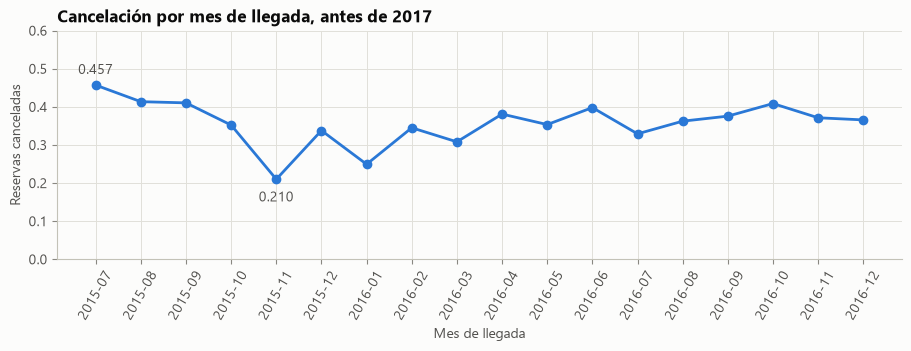

**Hallazgo.** La cancelación mensual va del 21.0 % (2015-11) al 45.7 % (2015-07). No es un valor estable.

,variant,roc_auc,roc_auc_std,gap
0,19_variables,0.8141,0.0301,0.0000
1,plus_month,0.8073,0.0307,-0.0068
2,plus_month_week_day,0.8065,0.0316,-0.0077
3,plus_year_month_week_day,0.8080,0.0322,-0.0061


In [3]:
by_month = (
    development.assign(mes=development[schema.ARRIVAL_DATE].dt.strftime("%Y-%m"))
    .groupby("mes")[target]
    .agg(reservas="size", cancelacion="mean")
)

figure, axis = new_figure(9, 3.4)
axis.plot(by_month.index, by_month["cancelacion"], "-o", color=plots.ACCENT, markersize=6)
axis.set_title("Cancelación por mes de llegada, antes de 2017")
axis.set_ylabel("Reservas canceladas")
axis.set_xlabel("Mes de llegada")
axis.set_ylim(0, 0.6)
axis.tick_params(axis="x", rotation=60)
# The lowest month sits in a valley, so its label goes below the line.
for month, offset in (
    (by_month["cancelacion"].idxmin(), -16),
    (by_month["cancelacion"].idxmax(), 8),
):
    axis.annotate(
        f"{by_month.loc[month, 'cancelacion']:.3f}",
        (month, by_month.loc[month, "cancelacion"]),
        xytext=(0, offset),
        textcoords="offset points",
        ha="center",
        color=plots.SECONDARY_INK,
    )
publish(figure, "eda_cancelacion_mes")

lowest = record("cancelacion_mes_min", by_month["cancelacion"].min(), "Mes con menos cancelación")
highest = record("cancelacion_mes_max", by_month["cancelacion"].max(), "Mes con más cancelación")
note(
    f"**Hallazgo.** La cancelación mensual va del {percent(lowest)} "
    f"({by_month['cancelacion'].idxmin()}) al {percent(highest)} "
    f"({by_month['cancelacion'].idxmax()}). No es un valor estable."
)
experiment("calendar")

**Decisión.** La evaluación oficial es **temporal**, con cuatro ventanas expansivas en 2016 y el test en 2017 ([ADR 0001](../docs/adr/0001-evaluacion-temporal.md)). Además, **quedan fuera el año, el mes, la semana y el día de llegada**: la tabla compara añadirlos, y `gap` es la diferencia pareada de ROC-AUC con las 19 variables. Añadir calendario no mejora en ninguna variante, porque un modelo no puede aprender de un año futuro que no ha visto.

## 3. Muchas filas están repetidas

**Por qué se mira.** Una reserva repetida puede caer a la vez en train y en test, y eso regala aciertos.

In [4]:
with_target = development[[*schema.INPUT_FEATURES, target]]
is_repeated = with_target.duplicated()
repeated = record(
    "duplicadas", is_repeated.mean(), "Filas repetidas según las 19 variables y el objetivo"
)
note(
    f"**Hallazgo.** El {percent(repeated)} de las filas repite exactamente otra, si se comparan "
    "las 19 variables de entrada y el objetivo. Una partición aleatoria las repartiría a los dos "
    "lados."
)
experiment("duplicates")

**Hallazgo.** El 35.9 % de las filas repite exactamente otra, si se comparan las 19 variables de entrada y el objetivo. Una partición aleatoria las repartiría a los dos lados.

,variant,roc_auc,roc_auc_std,gap
0,train_all_rows,0.8141,0.0301,0.0000
1,train_unique_rows,0.8116,0.0246,-0.0025


**Decisión.** Otra razón para no partir al azar. Se entrena con todas las filas, porque quitar las repetidas no mejora (`gap` negativo en la tabla), y **el ROC-AUC global nunca va solo**: se publica también con filas únicas. Notebook [`02_auditoria_fugas`](02_auditoria_fugas.ipynb) mide cuánto infla esto.

## 4. `deposit_type` casi decide por sí sola

**Por qué se mira.** Una variable que separa tan bien puede ser una fuga, o un artefacto de cómo se registraron los datos.

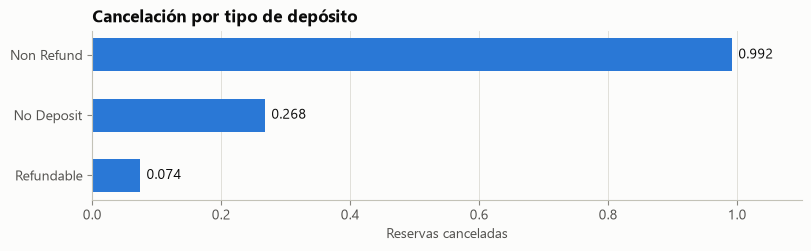

**Hallazgo.** `Non Refund` se cancela en el 99.2 % de los casos, y el 93.7 % de sus filas está repetido. Es difícil creer que pagar sin devolución haga cancelar más: apunta a tandas de reservas casi idénticas que se cancelan juntas.

,reservas,cancelacion,repetidas
deposit_type,,,
Refundable,135,0.0741,0.6593
No Deposit,67459,0.2677,0.2685
Non Refund,10460,0.9919,0.9373


In [5]:
by_deposit = (
    development.assign(repetida=is_repeated)
    .groupby("deposit_type")
    .agg(reservas=(target, "size"), cancelacion=(target, "mean"), repetidas=("repetida", "mean"))
    .sort_values("cancelacion")
)

figure, axis = new_figure(8, 2.4)
axis.barh(by_deposit.index, by_deposit["cancelacion"], color=plots.ACCENT, height=0.55)
for position, value in enumerate(by_deposit["cancelacion"]):
    axis.text(value + 0.01, position, f"{value:.3f}", va="center", color=plots.INK)
axis.set_xlim(0, 1.1)
axis.set_title("Cancelación por tipo de depósito")
axis.set_xlabel("Reservas canceladas")
axis.grid(visible=False, axis="y")
publish(figure, "eda_deposito")

non_refund = by_deposit.loc["Non Refund"]
record("non_refund_reservas", non_refund["reservas"], "Reservas Non Refund")
record("non_refund_cancelacion", non_refund["cancelacion"], "Cancelación de Non Refund")
record("non_refund_repetidas", non_refund["repetidas"], "Filas repetidas dentro de Non Refund")
record(
    "no_deposit_cancelacion",
    by_deposit.loc["No Deposit", "cancelacion"],
    "Cancelación de No Deposit",
)
note(
    f"**Hallazgo.** `Non Refund` se cancela en el {percent(non_refund['cancelacion'])} de los "
    f"casos, y el {percent(non_refund['repetidas'])} de sus filas está repetido. Es difícil "
    "creer que pagar sin devolución haga cancelar más: apunta a tandas de reservas casi "
    "idénticas que se cancelan juntas."
)
by_deposit

**Decisión.** **Se conserva, sin leerla como causa**, y la interfaz lo avisa. No consta que se conozca al reservar: el artículo la calcula con los pagos anteriores a la llegada o a la cancelación. Por eso se publica el rendimiento separado en `No Deposit` y `Non Refund`: la cifra global mezcla un problema muy difícil con uno trivial.

## 5. Variables que no se conocen al confirmar

**Por qué se mira.** Si una variable se rellena después de confirmar, el modelo aprende del futuro y la cifra no vale.

In [6]:
parking = development.loc[development["required_car_parking_spaces"] > 0, target]
record("parking_cancelacion", parking.mean(), "Cancelación de las reservas con plaza de parking")
changed_room = development["assigned_room_type"] != development["reserved_room_type"]
same_room_rate = development.loc[~changed_room, target].mean()
other_room_rate = development.loc[changed_room, target].mean()
portugal = development["country"] == "PRT"
portugal_rate = development.loc[portugal, target].mean()
other_country_rate = development.loc[~portugal, target].mean()

note(
    f"**Hallazgos.**\n\n"
    f"- Con plaza de parking se cancela el {percent(parking.mean())} de {count(len(parking))} "
    "reservas: la plaza se pide al llegar.\n"
    f"- Con otra habitación asignada se cancela el {percent(other_room_rate)}, frente al "
    f"{percent(same_room_rate)}: la asignación solo se conoce al llegar.\n"
    f"- Con `country` = `PRT` se cancela el {percent(portugal_rate)}, frente al "
    f"{percent(other_country_rate)}. Los autores del dataset explican que el país se corrige "
    "en el check-in, de modo que las canceladas conservan el valor por defecto."
)
pd.crosstab(development["reservation_status"], development[target])

**Hallazgos.**

- Con plaza de parking se cancela el 0.0 % de 5 197 reservas: la plaza se pide al llegar.
- Con otra habitación asignada se cancela el 4.8 %, frente al 41.7 %: la asignación solo se conoce al llegar.
- Con `country` = `PRT` se cancela el 56.9 %, frente al 19.7 %. Los autores del dataset explican que el país se corrige en el check-in, de modo que las canceladas conservan el valor por defecto.

is_canceled,0,1
reservation_status,,
Canceled,0,27599
Check-Out,49609,0
No-Show,0,846


**Decisión.** `reservation_status` repite el objetivo, como muestra la tabla. Las 12 variables prohibidas se listan con su motivo en [`schema.py`](../src/hotel_cancellation/schema.py), y un test falla si alguna llega al modelo. La data card recoge la evidencia de cada una.

## 6. Variables que se acumulan: `total_of_special_requests`

**Por qué se mira.** Una reserva cancelada deja de cambiar al cancelarse. Si una variable crece durante la vida de la reserva, las que se cancelan pronto tendrán valores bajos, y el modelo aprenderá eso, aunque al confirmar nadie lo sepa. `booking_changes`, que cuenta cambios por definición, hace de control positivo.

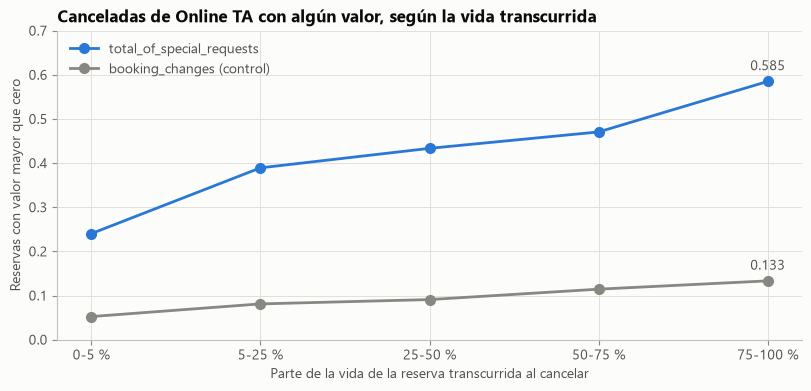

**Hallazgo.** En Online TA, el segmento mayor, las canceladas tienen alguna petición en el 24.0 % de los casos si cancelan en el primer tramo de vida, y en el 58.5 % si cancelan en el último. Crece más que el control.

,variant,roc_auc,roc_auc_std,gap
0,xgboost_19_variables,0.8141,0.0301,0.0000
1,xgboost_plus_special_requests,0.8481,0.0135,0.0340
2,random_forest_19_variables,0.8173,0.0231,0.0031
3,random_forest_plus_special_requests,0.8492,0.0171,0.0351


In [7]:
bins = pd.read_csv(settings.experiments_dir / "feature_availability_bins.csv")
control_bins = bins[bins["scope"] == "control"]
share_with_value = control_bins.pivot(
    index="life_bin", columns="variable", values="nonzero_share"
).loc[lambda table: sorted(table.index, key=lambda name: int(name.split("_")[0]))]
share_with_value.index = [name.replace("_", "-") + " %" for name in share_with_value.index]

figure, axis = new_figure(8, 3.8)
series = (
    ("total_of_special_requests", plots.ACCENT, "total_of_special_requests"),
    ("booking_changes", plots.MUTED, "booking_changes (control)"),
)
for column, color, label in series:
    values = share_with_value[column]
    axis.plot(values.index, values, "-o", color=color, markersize=7, label=label)
    axis.annotate(
        f"{values.iloc[-1]:.3f}",
        (values.index[-1], values.iloc[-1]),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        color=plots.SECONDARY_INK,
    )
axis.set_title("Canceladas de Online TA con algún valor, según la vida transcurrida")
axis.set_xlabel("Parte de la vida de la reserva transcurrida al cancelar")
axis.set_ylabel("Reservas con valor mayor que cero")
axis.set_ylim(0, 0.7)
axis.legend(loc="upper left")
publish(figure, "eda_acumulacion")

requests_first = share_with_value["total_of_special_requests"].iloc[0]
requests_last = share_with_value["total_of_special_requests"].iloc[-1]
note(
    f"**Hallazgo.** En Online TA, el segmento mayor, las canceladas tienen alguna petición en el "
    f"{percent(requests_first)} de los casos si cancelan en el primer tramo de vida, y en el "
    f"{percent(requests_last)} si cancelan en el último. Crece más que el control."
)
experiment("special_requests")

**Decisión.** **Queda fuera**, como `booking_changes`. El diagnóstico es observacional, porque quien cancela enseguida puede ser otro tipo de cliente, y la tabla muestra que esa variable subiría mucho la cifra en validación. Por eso se publica un **escenario informativo con ella**, que no puede cambiar el campeón ([ADR 0002](../docs/adr/0002-momento-de-prediccion-y-variables-excluidas.md)).

## 7. La antelación importa, pero no en línea recta

**Por qué se mira.** Si la relación no es lineal, un modelo lineal se quedará corto y los árboles deberían hacerlo mejor.

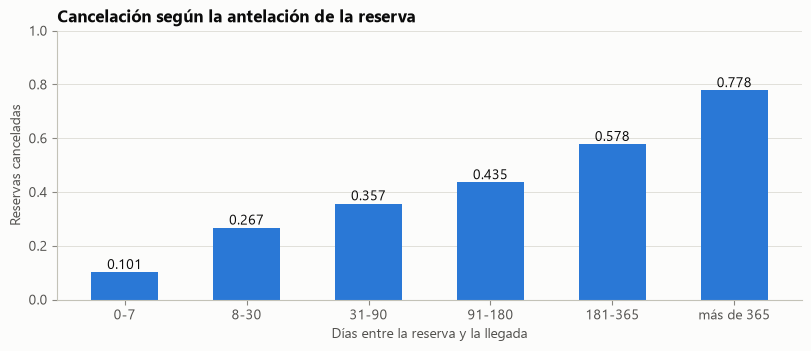

**Hallazgo.** De 10.1 % con menos de una semana a 77.8 % con más de un año, y no sube por igual en cada tramo.

,variant,roc_auc,roc_auc_std,gap
0,depth_6_regularized,0.8141,0.0301,0.0000
1,depth_16,0.7961,0.0335,-0.0180
2,depth_3,0.8070,0.0248,-0.0071


In [8]:
edges = [-1, 7, 30, 90, 180, 365, development["lead_time"].max()]
names = ["0-7", "8-30", "31-90", "91-180", "181-365", "más de 365"]
by_lead_time = (
    development.assign(antelacion=pd.cut(development["lead_time"], bins=edges, labels=names))
    .groupby("antelacion", observed=True)[target]
    .agg(reservas="size", cancelacion="mean")
)

figure, axis = new_figure(8, 3.4)
axis.bar(by_lead_time.index, by_lead_time["cancelacion"], color=plots.ACCENT, width=0.55)
for position, value in enumerate(by_lead_time["cancelacion"]):
    axis.text(position, value + 0.012, f"{value:.3f}", ha="center", color=plots.INK)
axis.set_title("Cancelación según la antelación de la reserva")
axis.set_xlabel("Días entre la reserva y la llegada")
axis.set_ylabel("Reservas canceladas")
axis.set_ylim(0, 1)
axis.grid(visible=False, axis="x")
publish(figure, "eda_antelacion")

record("antelacion_baja", by_lead_time["cancelacion"].iloc[0], "Cancelación con 0-7 días")
record("antelacion_alta", by_lead_time["cancelacion"].iloc[-1], "Cancelación con más de 365 días")
note(
    f"**Hallazgo.** De {percent(by_lead_time['cancelacion'].iloc[0])} con menos de una semana a "
    f"{percent(by_lead_time['cancelacion'].iloc[-1])} con más de un año, y no sube por igual en "
    "cada tramo."
)
experiment("tree_depth")

**Decisión.** Se comparan regresión logística, árbol, Random Forest, XGBoost y MLP. Los árboles recogen esta forma sin transformar la variable, pero **conviene regularizarlos**: la tabla compara profundidades de XGBoost, y los muy profundos empeoran en el futuro.

## 8. `adr` tiene valores imposibles y una cola larga

**Por qué se mira.** Los valores imposibles se limpian; una cola larga afecta a los modelos que escalan, no a los árboles.

In [9]:
adr = development["adr"]
record("adr_mediana", adr.median(), "Mediana de adr")
record("adr_p99", adr.quantile(0.99), "Percentil 99 de adr")
record("adr_max", adr.max(), "Máximo de adr tras limpiar")
record("adr_cero", (adr == 0).mean(), "Filas con adr igual a 0")
note(
    f"**Hallazgo.** Tras limpiar, la mediana es {adr.median():.1f}, el percentil 99 es "
    f"{adr.quantile(0.99):.1f} y el máximo, {adr.max():.1f}. El {percent((adr == 0).mean())} de "
    "las filas tiene tarifa 0."
)
adr.describe().to_frame().T

**Hallazgo.** Tras limpiar, la mediana es 89.2, el percentil 99 es 235.0 y el máximo, 508.0. El 1.1 % de las filas tiene tarifa 0.

,count,mean,std,min,25%,50%,75%,max
adr,78054.0000,95.9170,43.7991,0.0000,65.0000,89.2500,117.9000,508.0000


**Decisión.** Se eliminan las filas con `adr` negativo o de 5400 o más. Ese corte salió de una auditoría previa que había visto 2017, y el protocolo lo declara. No se crean variables derivadas como `adr` por noche, porque la tarifa ya es diaria. Se conserva `adr`, aunque el CSV guarda su último valor y no se puede demostrar que no se sobrescriba: es una limitación declarada.

## 9. Nulos y categorías con muchos valores

**Por qué se mira.** Decide cómo se imputa y cómo se codifica sin añadir transformadores propios.

In [10]:
missing = development[list(schema.RAW_COLUMNS)].isna().mean()
missing = missing[missing > 0].sort_values(ascending=False).rename("nulos")
agent_counts = development["agent"].value_counts()
rare_agents = agent_counts[agent_counts < 50]
record("company_nulos", missing["company"], "Nulos en company")
record("agent_nulos", missing["agent"], "Nulos en agent")
record("agent_valores", agent_counts.size, "Valores distintos de agent")
record("agent_raros", rare_agents.size, "Valores de agent con menos de 50 filas")
note(
    f"**Hallazgo.** `company` está vacía en el {percent(missing['company'])} de las filas. "
    f"`agent` tiene {agent_counts.size} valores, y {rare_agents.size} no llegan a 50 filas, "
    f"aunque juntos solo suman el {percent(rare_agents.sum() / len(development))} del total."
)
display(missing.to_frame())
display(experiment("company"))
experiment("encodings")

**Hallazgo.** `company` está vacía en el 94.4 % de las filas. `agent` tiene 284 valores, y 185 no llegan a 50 filas, aunque juntos solo suman el 2.9 % del total.

,nulos
company,0.9436
agent,0.1344
country,0.0050
children,0.0001


,variant,roc_auc,roc_auc_std,gap
0,19_variables,0.8141,0.0301,0.0000
1,plus_company,0.8142,0.0293,0.0001


,variant,roc_auc,roc_auc_std,gap
0,one_hot_min_frequency,0.8141,0.0301,0.0000
1,target_agent_contiguous_folds,0.8077,0.0258,-0.0064
2,target_all_contiguous_folds,0.7996,0.0224,-0.0146
3,target_agent_shuffled_folds,0.8115,0.0264,-0.0026
4,ordinal,0.8096,0.0284,-0.0045


**Decisión.** `company` queda fuera: la primera tabla muestra que añadirla no aporta. `agent` se lee como texto, para que `9` no acabe siendo `9.0`, y se imputa. `OneHotEncoder(min_frequency=50, handle_unknown="infrequent_if_exist")` agrupa los valores raros y admite los nuevos, y la segunda tabla muestra que ninguna otra codificación lo supera. Así el pipeline usa solo clases de scikit-learn, y el artefacto no depende del paquete. El valor 50 también salió de la auditoría previa, y se declara.

## 10. Segmentos y hoteles

**Por qué se mira.** Si un grupo se comporta de forma muy distinta, puede que convenga un modelo aparte, y hay que medirlo por separado.

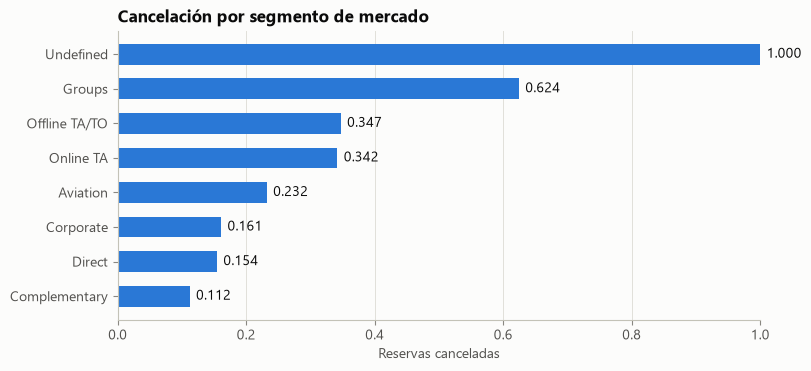

,reservas,cancelacion
hotel,,
City Hotel,51502,0.4153
Resort Hotel,26552,0.2658


,variant,roc_auc,roc_auc_std,gap
0,global_model,0.8141,0.0301,0.0000
1,one_model_per_hotel,0.8061,0.0266,-0.0081


In [11]:
by_segment = (
    development.groupby("market_segment")[target]
    .agg(reservas="size", cancelacion="mean")
    .sort_values("cancelacion")
)
figure, axis = new_figure(8, 3.6)
axis.barh(by_segment.index, by_segment["cancelacion"], color=plots.ACCENT, height=0.6)
for position, value in enumerate(by_segment["cancelacion"]):
    axis.text(value + 0.01, position, f"{value:.3f}", va="center", color=plots.INK)
axis.set_xlim(0, 1)
axis.set_title("Cancelación por segmento de mercado")
axis.set_xlabel("Reservas canceladas")
axis.grid(visible=False, axis="y")
publish(figure, "eda_segmento")

by_hotel = development.groupby("hotel")[target].agg(reservas="size", cancelacion="mean")
record("city_cancelacion", by_hotel.loc["City Hotel", "cancelacion"], "Cancelación en City Hotel")
record(
    "resort_cancelacion",
    by_hotel.loc["Resort Hotel", "cancelacion"],
    "Cancelación en Resort Hotel",
)
display(by_hotel)
experiment("per_hotel")

**Decisión.** Un **solo modelo global**: la tabla muestra que un modelo por hotel empeora. El rendimiento se publica por hotel y por segmento, porque la cifra global esconde diferencias grandes.

## 11. Clases moderadamente desequilibradas

**Por qué se mira.** Decide la métrica principal y si hace falta balancear.

In [12]:
note(
    f"**Hallazgo.** La clase positiva es el {percent(prevalence)}. No es un desequilibrio extremo. "
    f"Un clasificador que nunca avise acierta el {percent(1 - prevalence)}, de modo que la "
    "accuracy engaña."
)
experiment("balancing")

**Hallazgo.** La clase positiva es el 36.4 %. No es un desequilibrio extremo. Un clasificador que nunca avise acierta el 63.6 %, de modo que la accuracy engaña.

,variant,roc_auc,roc_auc_std,gap
0,xgboost_none,0.8141,0.0301,0.0000
1,xgboost_scale_pos_weight,0.8133,0.0292,-0.0008
2,xgboost_smote,0.8128,0.0282,-0.0013
3,xgboost_undersampling,0.8125,0.0291,-0.0016
4,logistic_none,0.7923,0.0182,-0.0219
5,logistic_class_weight,0.7918,0.0175,-0.0223
6,logistic_smote,0.7898,0.0172,-0.0243
7,logistic_undersampling,0.7908,0.0171,-0.0233


**Decisión.** La métrica principal es el **ROC-AUC**: está en la lista del enunciado, no depende del umbral y no se deja engañar por la proporción de clases. El campeón **no usa balanceo**: la tabla muestra que SMOTE, undersampling y los pesos de clase no mejoran, y además distorsionan la probabilidad, que aquí se usa para decidir con costes.

## Resumen: de cada hallazgo a su decisión

| Hallazgo | Decisión | Dónde se contrasta |
|---|---|---|
| La cancelación cambia mes a mes | Evaluación temporal; sin variables de calendario | `calendar.csv` |
| Muchas filas repetidas | Sin partición aleatoria; métrica también con filas únicas | `duplicates.csv` |
| `Non Refund` casi siempre se cancela | Se conserva, y se publica separada | `segments.csv`, tras el test |
| Variables conocidas después de confirmar | 12 variables prohibidas, con un test de guarda | `schema.py` |
| `total_of_special_requests` se acumula | Fuera, con un escenario informativo | `special_requests.csv` |
| La antelación no es lineal | Comparar árboles, y regularizarlos | `tree_depth.csv` |
| `adr` con valores imposibles | Limpieza, sin variables derivadas | Data card |
| `company` vacía y `agent` con muchos valores | `company` fuera; `agent` con `min_frequency=50` | `company.csv`, `encodings.csv` |
| Dos hoteles con niveles distintos | Modelo global, y métricas por hotel | `per_hotel.csv` |
| Clases moderadamente desequilibradas | ROC-AUC principal, sin balanceo | `balancing.csv` |

In [13]:
folder = settings.outputs_dir / "eda"
folder.mkdir(exist_ok=True)
table = pd.DataFrame(findings).round(6)
table.to_csv(folder / "hallazgos.csv", index=False, lineterminator="\n")
table

,clave,valor,descripcion
0,filas,78054.0000,Filas de desarrollo
1,prevalencia,0.3644,Cancelación en desarrollo
2,cancelacion_mes_min,0.2101,Mes con menos cancelación
3,cancelacion_mes_max,0.4572,Mes con más cancelación
4,duplicadas,0.3588,Filas repetidas según las 19 variables y el ob...
5,non_refund_reservas,10460.0000,Reservas Non Refund
6,non_refund_cancelacion,0.9919,Cancelación de Non Refund
7,non_refund_repetidas,0.9373,Filas repetidas dentro de Non Refund
8,no_deposit_cancelacion,0.2677,Cancelación de No Deposit
9,parking_cancelacion,0.0000,Cancelación de las reservas con plaza de parking
